### References

*   **GEKKO Optimization Suite Article:**
    Beal, L. D. R., Hill, D., Martin, R. A., & Hedengren, J. D. (2018). *GEKKO Optimization Suite*. Processes, 6(8), 106. doi.org

*   **APMonitor Course Website (ME575):**
    Hedengren, J. D. (n.d.). *Design Optimization (ME 575)*. APMonitor. Retrieved January 9, 2026, from https://apmonitor.com/me575/index.php/Main/HomePage

*   **Mr. P Solver (YouTube Channel):**
    Mr. P Solver. (n.d.). *Home* [YouTube channel]. YouTube. Retrieved January 9, 2026, from https://www.youtube.com/@MrPSolver

*   **The OR Book (Textbook):**
    Winston, W. L. (2004). *Operations Research: Applications and Algorithms* (4th ed.). Thomson Brooks/Cole.


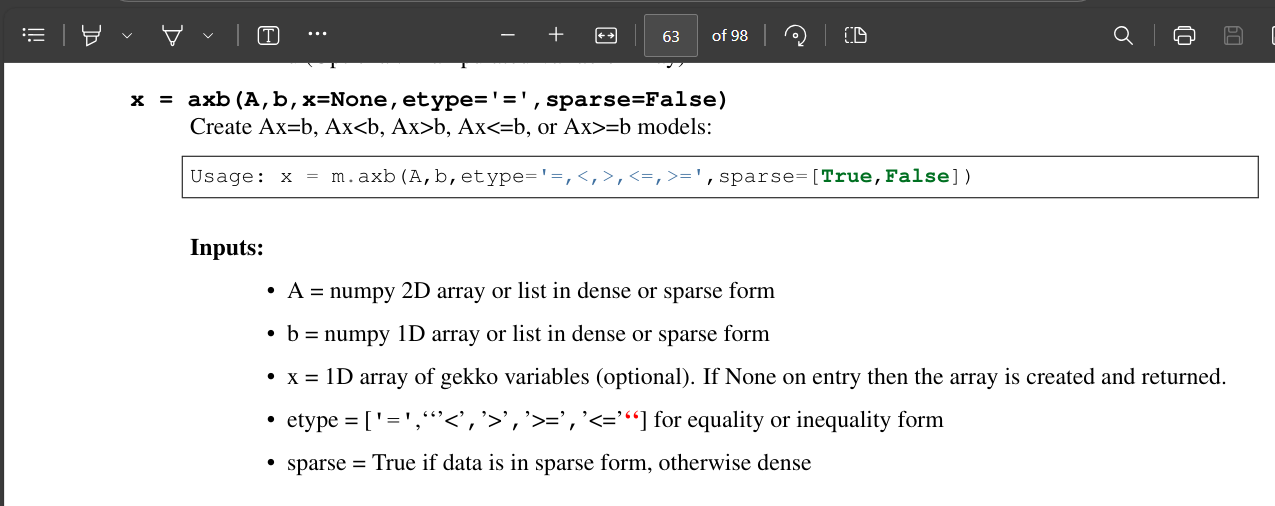

In [101]:
b[0]

np.int64(500)

In [16]:
# pg 17 from gekko docs,more compact form in the next cell
from gekko import GEKKO

# Simple version
m = GEKKO(remote=False)
#defineparameter
eq=m.Param(value=40)
#initialize variables
x1,x2,x3,x4 =[m.Var(lb=1,ub=5) for i in range(4)]
#initialvalues
x1.value=1
x2.value=5
x3.value=5
x4.value=1
#Equations
m.Equation(x1*x2*x3*x4>=25)
m.Equation(x1**2+x2**2+x3**2+x4**2==eq)
#Objective
m.Minimize(x1*x4*(x1+x2+x3)+x3)
#Setglobaloptions
m.options.IMODE=3#steadystate optimization
#Solvesimulation
m.solve(disp=False)
#Results
print('')
print('Results')
print('x1:'+str(x1.value))
print('x2:'+str(x2.value))
print('x3:'+str(x3.value))
print('x4:'+str(x4.value))


Results
x1:[1.000000057]
x2:[4.74299963]
x3:[3.8211500283]
x4:[1.3794081795]


In [5]:
from gekko import GEKKO
import numpy as np
m=GEKKO(remote=False)
x=m.Array(m.Var,4,value=1,lb=1,ub=5)
x1,x2,x3,x4 =x #renamevariables
x2.value=5;x3.value=5 #changeguess
m.Equation(np.prod(x)>=25) #prod>=25
m.Equation(m.sum([xi**2 for xi in x])==40)#sum=40
m.Minimize(x1*x4*(x1+x2+x3)+x3)# objective
m.solve(disp=False)
print(x)

[[1.0000000339] [4.7429996271] [3.8211500196] [1.3794082228]]


In [12]:
from gekko import GEKKO
import numpy as np
m=GEKKO(remote=False)
x=m.Array(m.Var,4,value=1,lb=1,ub=5)
#x1,x2,x3,x4 =x #renamevariables
x[1].value=5;x[2].value=5 #changeguess
m.Equation(np.prod(x)>=25) #prod>=25
m.Equation(m.sum([xi**2 for xi in x])==40)#sum=40
m.Minimize(x[0]*x[3]*(x[0]+x[1]+x3)+x[2])# objective
m.solve(disp=False)
print(x)

[[1.0000000339] [4.7429996271] [3.8211500196] [1.3794082228]]


In [60]:
i=1
while i <= 8:
    print(i)
    i+=1
    

1
2
3
4
5
6
7
8


### pg89,pg90,116 onwards
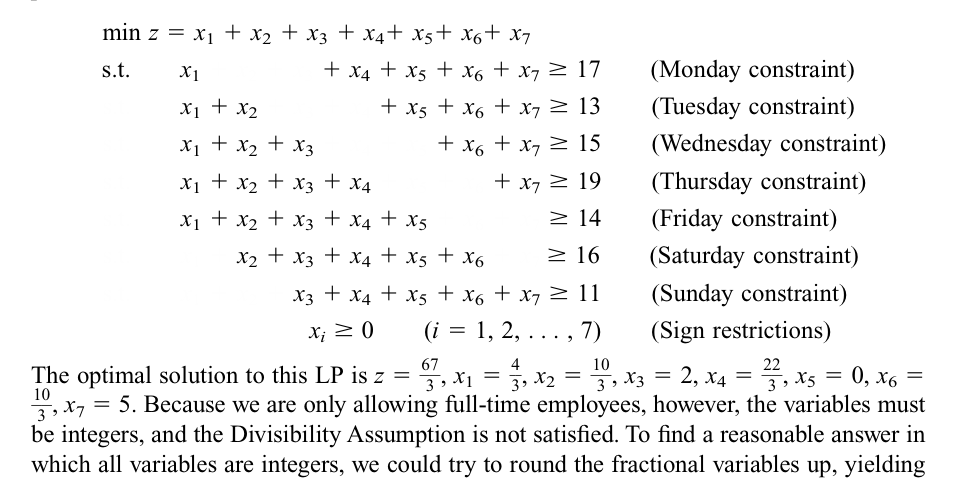

In [78]:
D=[17,13,15,19,14,16,11]
wdays=5 # must be below len(D)
h=len(D)-wdays #holidays

m = GEKKO(remote=False)
x = m.Array(m.Var,len(D),lb=0,integer=True)
C=np.ones(len(D))

#generate matrix A
Raws=[None]*len(D) #elements shall be raws
i=1
while len(D[(i+h):])>=1:
    Raws1=np.zeros(len(D))
    Raws1[:i]=1
    Raws1[(i+h):]=1
    Raws[(i-1)]=Raws1
    #print(Raws)
    i+=1

while i <=len(D):
    Raws1=np.zeros(len(D))
    Raws1[(i-wdays):i]=1
    Raws[(i-1)]=Raws1
    i+=1
    
A=np.array(Raws) # bravo finished creating A
b=np.array(D)

m.Minimize(C@x)
Ax = A@x
m.Equations([Ax[i]>=b[i] for i in range(len(b))])

m.options.SOLVER=1 #to make sure its integer
m.solve(disp=False)

# Print the results
print("Objective function: ", m.options.objfcnval)
print("Optimal solution: ", x)
print("then A is ")
print(A)
print("check if this problem may have multiple solutions pg 90 ???")

Objective function:  23.0
Optimal solution:  [[5.0] [4.0] [2.0] [7.0] [0.0] [3.0] [2.0]]
then A is 
[[1. 0. 0. 1. 1. 1. 1.]
 [1. 1. 0. 0. 1. 1. 1.]
 [1. 1. 1. 0. 0. 1. 1.]
 [1. 1. 1. 1. 0. 0. 1.]
 [1. 1. 1. 1. 1. 0. 0.]
 [0. 1. 1. 1. 1. 1. 0.]
 [0. 0. 1. 1. 1. 1. 1.]]
check if this problem may have multiple solutions pg 90 ???


In [54]:
from gekko import GEKKO
import numpy as np
m=GEKKO(remote=False)
x=m.Array(m.Var,7,value=1,lb=0,integer=True)
x1,x2,x3,x4,x5,x6,x7 =x #renamevariables
#x2.value=5;x3.value=5 #changeguess
m.Equation(x1+x4+x5+x6+x7>=17) 
m.Equation(x1+x2+x5+x6+x7>=13)
m.Equation(x1+x2+x3+x6+x7>=15)
m.Equation(x1+x2+x3+x4+x7>=19)
m.Equation(x1+x2+x3+x4+x5>=14)
m.Equation(x2+x3+x4+x5+x6>=16)
m.Equation(x3+x4+x5+x6+x7>=11)
m.Minimize(np.sum(x))# objective
#m.Minimize(x1+x2+x3+x4+x5+x6+x7)
m.options.SOLVER = 1
m.solve(disp=False)
print(x,m.options.objfcnval)


[[7.0] [4.0] [2.0] [7.0] [0.0] [3.0] [0.0]] 23.0


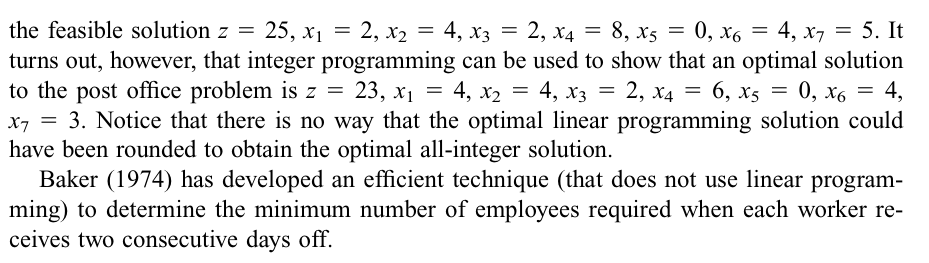
so it appears their are more than two silutions in this

In [198]:
np.sum([7.0,4.0,2.0,7.0,0.0,3.0,0.0])

np.float64(23.0)

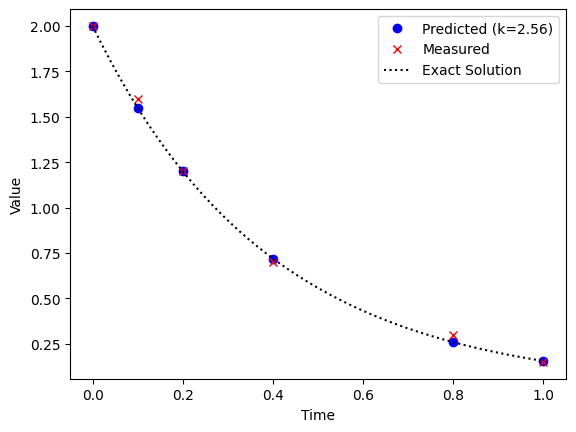

In [176]:
#IMODE=5 application:
from gekko import GEKKO
t_data = [0, 0.1, 0.2, 0.4, 0.8, 1]
x_data = [2.0, 1.6, 1.2, 0.7, 0.3, 0.15]
m = GEKKO(remote=False)
m.time = t_data
x = m.CV(value=x_data); x.FSTATUS = 1 # fit to measurement
k = m.FV(); k.STATUS = 1
# adjustable parameter
m.Equation(x.dt()==-k * x)
# differential equation
m.options.IMODE = 5 # dynamic estimation
m.options.NODES = 5 # collocation nodes
m.solve(disp=False) # display solver output
k = k.value[0]
import numpy as np
import matplotlib.pyplot as plt # plot solution
plt.plot(m.time,x.value,'bo',\
label='Predicted (k='+str(np.round(k,2))+')')
plt.plot(m.time,x_data,'rx',label='Measured')
# plot exact solution
t = np.linspace(0,1); xe = 2*np.exp(-k*t)
plt.plot(t,xe,'k:',label='Exact Solution')
plt.legend()
plt.xlabel('Time'),plt.ylabel('Value')
plt.show()

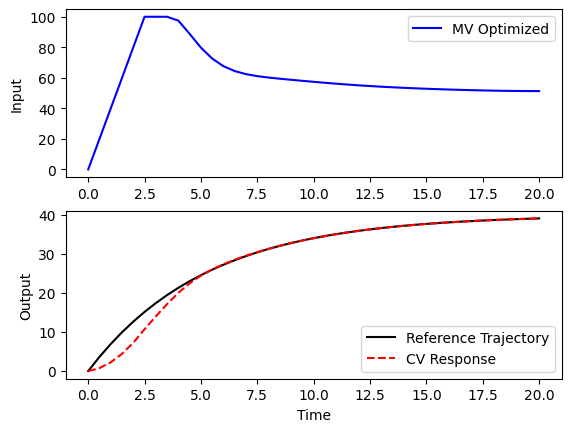

In [12]:
#ExampleMPC(IMODE=6)application:
from gekko import GEKKO
import numpy as np
import matplotlib.pyplot as plt
m=GEKKO(remote=False)
m.time=np.linspace(0,20,41)
#Parameters
mass=500
b=m.Param(value=50)
K=m.Param(value=0.8)
#Manipulated variable
p=m.MV(value=0,lb=0,ub=100)
p.STATUS=1 #allow optimizer to change
p.DCOST= 0.1#smooth out gas pedal movement
p.DMAX=20 #slow down change of gaspedal
#Controlled Variable
v=m.CV(value=0)
v.STATUS=1 #add the SP to the objective
m.options.CV_TYPE=2#squarederror
v.SP=40 #setpoint
v.TR_INIT = 1#setpointtrajectory
v.TAU=5 #timeconstantoftrajectory
#Process model
m.Equation(mass*v.dt()==-v*b+K*b*p)
m.options.IMODE = 6 # control
m.solve(disp=False)
# get additional solution information
import json
with open(m.path+'//results.json') as f:
    results = json.load(f)
plt.figure()
plt.subplot(2,1,1)
plt.plot(m.time,p.value,'b-',label='MV Optimized')
plt.legend()
plt.ylabel('Input')
plt.subplot(2,1,2)
plt.plot(m.time,results['v1.tr'],'k-',label='Reference Trajectory')
plt.plot(m.time,v.value,'r--',label='CV Response')
plt.ylabel('Output')
plt.xlabel('Time')
plt.legend(loc='best')
plt.show()

also review the docs aspescially the links

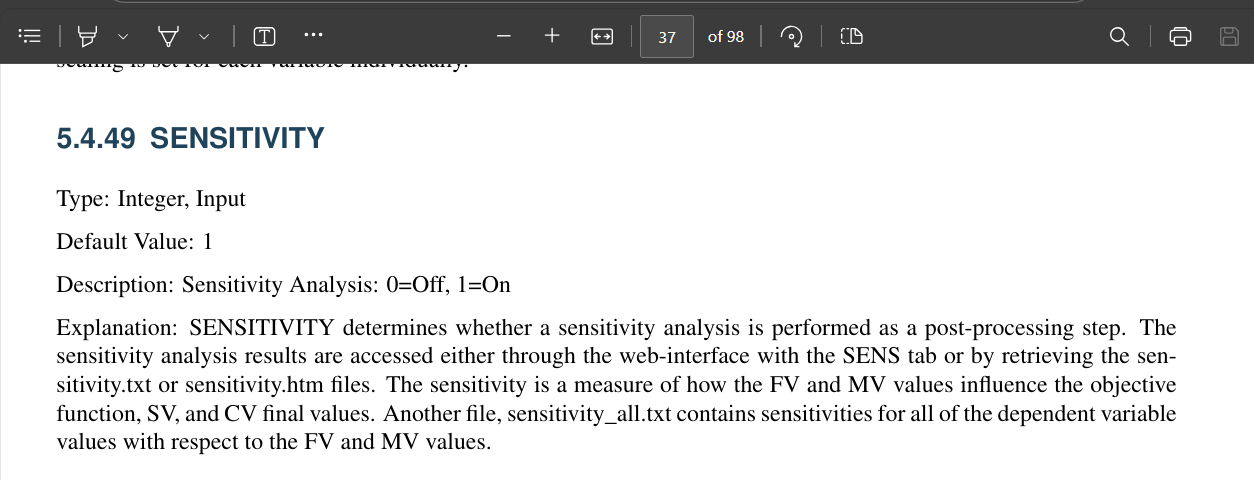

(pg 56)The following example demonstrates the use of a 3x2 Array, a Parameter, Intermediates, and an Objective. The array values are initialized to
2.0 and bounds are set to-10.0 to 10.0

In [4]:
from gekko import GEKKO
m = GEKKO(remote=False)
# variable array dimension, parhaps useful in network anaylis??
n = 3 # rows
p = 2 # columns
# create array
x = m.Array(m.Var,(n,p))
for i in range(n):
    for j in range(p):
        x[i,j].value = 2.0
        x[i,j].lower =-10.0
        x[i,j].upper = 10.0
# create parameter
y = m.Param(value = 1.0)
# sum columns
z = [None]*p
for j in range(p):
    z[j] = m.Intermediate(sum([x[i,j] for i in range(n)]))
# objective which may be any fuction of the variables in the array??
m.Obj(sum([ (z[j]-1)**2 + y for j in range(p)]))
# minimize objective
m.solve(disp=False)
print('x:', x)
print('z:', z)

x: [[[0.33333333333] [0.33333333333]]
 [[0.33333333333] [0.33333333333]]
 [[0.33333333333] [0.33333333333]]]
z: [[1.0], [1.0]]


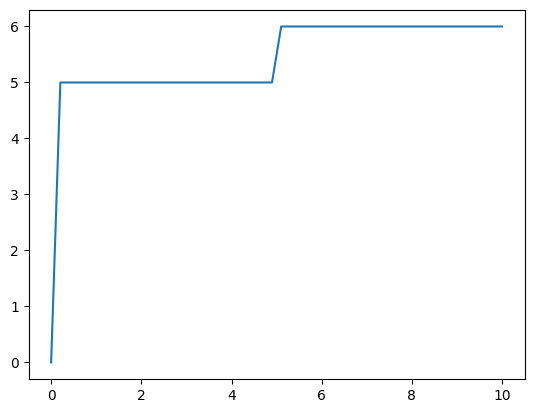

In [21]:
#pg60
x1 = m.Const(5)
x2 = m.Const(6)
t = m.Var(0)
m.Equation(t.dt()==1)
m.time = np.linspace(0,10)
y = m.if2(t-5,x1,x2)
m.options.IMODE = 6
m.solve(disp=False)
#import matplotlib.pyplot as plt
plt.plot(m.time,y)
plt.show()

In [5]:
#pg61
import numpy as np
import matplotlib.pyplot as plt
from gekko import GEKKO
m = GEKKO(remote=False)
p = m.Param()
y = m.if3(p-4,p**2,p+1) # like an integer choosing staff??
# solve with condition<0
p.value = 3
m.solve(disp=False)
print(y.value)
# solve with condition>=0
p.value = 5
m.solve(disp=False)
print(y.value)

[9.0]
[6.0]


In [35]:
#pg62
y = m.sos1([19.05, 25.0, 29.3, 30.2])
m.Obj(y) # select the minimum value
m.solve(disp=False)
print(y.value)

[19.05]


In [7]:
m.cleanup()

In [26]:
m = GEKKO(remote=False)
x = m.Array(m.Var,5,lb=0,ub=1)
C=[-13, -16,-16,-14,-39]
A=[[11,53,5,5,29],
   [3,6,5,1,34]]
b = [40,20]
m.Minimize(C@x)
Ax = A@x
m.Equations([Ax[i]<=b[i] for i in range(len(b))])
m.options.SOLVER=1 #to make sure its integer
m.solve(disp=False)

# Print the results
print("Objective function: ", -m.options.objfcnval)
print("Optimal solution: ", x)

Objective function:  57.449017199
Optimal solution:  [[1.0] [0.20085995086] [1.0] [1.0] [0.28808353808]]


In [28]:
m = GEKKO(remote=False)
x = m.Array(m.Var,5,lb=0,ub=1)
C=np.array([-13, -16,-16,-14,-39])
A=np.array([[11,53,5,5,29],
   [3,6,5,1,34]])
b = np.array([40,20])
m.Minimize(C@x)
Ax = A@x
m.Equations([Ax[i]<=b[i] for i in range(len(b))])
m.options.SOLVER=1 #to make sure its integer
m.solve(disp=False)

# Print the results
print("Objective function: ", -m.options.objfcnval)
print("Optimal solution: ", x)

Objective function:  57.449017199
Optimal solution:  [[1.0] [0.20085995086] [1.0] [1.0] [0.28808353808]]
